# The Palisades fire from a virtual Zarr cube

The cube holds two weeks of GOES-18 fire detections (2025-01-07 to 2025-01-20 UTC) for the full CONUS scene. This notebook uses the Palisades fire as its example and plots its fire radiative power (FRP), then maps one scan. Change `AOI_BOUNDS` and `MAP_BOUNDS` to look at any other place in the scene. The notebook starts from the Portolan catalog, not from a URL to the data, so it also tests how far the catalog metadata gets a reader.

The cube is virtual. It holds byte-range references into NOAA's netCDF files in the public `noaa-goes18` bucket. Every pixel this notebook reads comes from NOAA's bucket. The approach comes from Earthmover's [GOES-16 virtual Zarr post](https://www.earthmover.io/blog/virtual-zarr/).

Run it from the repository with:

```bash
uv sync --group examples
uv run --group examples jupyter nbconvert --to notebook --execute --inplace examples/palisades-frp.ipynb
```

The map in section 4 fetches basemap tiles from OpenStreetMap, so the notebook needs network access beyond NOAA's bucket.

In [1]:
import os
import sys
import time
from pathlib import Path

# Icechunk reads this when it is imported. The notebook only reads, so keep the
# log to errors and drop the warning about concurrent commits to local storage.
os.environ.setdefault("ICECHUNK_LOG", "error")

import contextily as cx
import geopandas as gpd
import icechunk
import matplotlib.pyplot as plt
import numpy as np
import pyproj
import pystac
import rioxarray  # noqa: F401  (registers the .rio accessor)
import xarray as xr
from shapely.geometry import box

ROOT = Path.cwd().parent if Path.cwd().name == "examples" else Path.cwd()
sys.path.insert(0, str(ROOT / "tools"))
from publish import load_config  # noqa: E402

In [2]:
# The catalog to start from. After the catalog is published, set this to the
# public catalog.json URL and set LOCAL_DATA to None.
CATALOG = ROOT / "catalog" / "catalog.json"

# Until the data is published, asset hrefs that start with the public base are
# read from this local directory instead (data_dir in catalog.publish.yaml).
LOCAL_DATA = ROOT / "local" / "publish"

# The snapshot to read. A tag pins the exact data this notebook ran against,
# even after the cube grows. If the repository has no such tag, the notebook
# reads the head of main and says so.
SNAPSHOT_TAG = "demo-2025-01"

# Bounds are (west, south, east, north) in EPSG:4326 degrees.
# AOI_BOUNDS is the area summed for the FRP time series. This one is the
# Palisades fire, and it leaves out the Eaton fire, which started the same
# evening about 40 km to the east.
AOI_BOUNDS = (-118.70, 34.00, -118.45, 34.15)
# MAP_BOUNDS is the wider area drawn on the map. It holds both fires.
MAP_BOUNDS = (-119.20, 33.70, -117.80, 34.50)

AOI = gpd.GeoDataFrame({"name": ["Palisades AOI"]}, geometry=[box(*AOI_BOUNDS)], crs="EPSG:4326")

## 1. Find the data through the catalog

The root catalog links to the collection. The collection says what the cube holds and how to open it.

In [3]:
root = pystac.Catalog.from_file(str(CATALOG))
collection = next(c for c in root.get_all_collections() if c.id == "goes-18-fdcc")
asset = collection.assets["icechunk"]

print(collection.title)
print("time:      ", collection.extent.temporal.intervals[0])
print("variables: ", list(collection.extra_fields["cube:variables"]))
print("asset href:", asset.href)
print("media type:", asset.media_type)
print("open with: ", asset.extra_fields["xarray:open_kwargs"])

GOES-18 ABI L2 Fire/Hot Spot Characterization, CONUS (virtual Zarr)
time:       [datetime.datetime(2025, 1, 7, 0, 2, 35, tzinfo=tzutc()), datetime.datetime(2025, 1, 20, 23, 57, 35, tzinfo=tzutc())]
variables:  ['Area', 'DQF', 'Mask', 'Power', 'Temp', 'fire_radiative_power_outlier_pixel_count', 'geospatial_lat_lon_extent', 'fire_area_outlier_pixel_count', 'fire_temperature_outlier_pixel_count', 'goes_imager_projection', 'maximum_fire_area', 'maximum_fire_radiative_power', 'minimum_fire_area', 'mean_fire_radiative_power', 'maximum_fire_temperature', 'minimum_fire_radiative_power', 'percent_uncorrectable_L0_errors', 'mean_fire_temperature', 'standard_deviation_fire_radiative_power', 'standard_deviation_fire_area', 'mean_fire_area', 'minimum_fire_temperature', 'percent_uncorrectable_GRB_errors', 'standard_deviation_fire_temperature', 'total_number_of_pixels_with_fire_temperature', 'total_number_of_pixels_with_fire_radiative_power', 'total_number_of_pixels_with_fire_area', 'total_number_of_

## 2. Open the cube

The asset says the cube is a Zarr v3 group in an Icechunk repository, and it gives the `xarray` arguments. It does not say that the chunks live in another bucket. Icechunk refuses to read a virtual chunk from a location the reader has not authorized, so the reader must configure NOAA's bucket as a *virtual chunk container* by hand. No field in the STAC `zarr` or `xarray` extensions carries that today. The collection README documents it, and this notebook copies it from there. This gap is one of the open questions for Zarr in Portolan ([portolan-spec#132](https://github.com/portolan-sdi/portolan-spec/issues/132)).

In [4]:
public_base = load_config(ROOT / "catalog.publish.yaml")["public_base"].rstrip("/")


def storage_for(href: str) -> icechunk.Storage:
    """Icechunk storage for an asset href, read locally until the data is published."""
    if LOCAL_DATA is not None and href.startswith(public_base):
        local = LOCAL_DATA / href[len(public_base):].strip("/")
        return icechunk.local_filesystem_storage(str(local))
    return icechunk.http_storage(href)


# Not in the catalog metadata. Copied from the collection README.
NOAA = "https://noaa-goes18.s3.amazonaws.com/"
config = icechunk.RepositoryConfig.default()
config.set_virtual_chunk_container(icechunk.VirtualChunkContainer(NOAA, icechunk.http_store()))
credentials = icechunk.containers_credentials({NOAA: icechunk.Credentials.HttpAccess()})

repo = icechunk.Repository.open(
    storage_for(asset.href), config=config, authorize_virtual_chunk_access=credentials
)
if SNAPSHOT_TAG in repo.list_tags():
    session = repo.readonly_session(tag=SNAPSHOT_TAG)
    print(f"reading tag {SNAPSHOT_TAG}")
else:
    session = repo.readonly_session(branch="main")
    print(f"no tag {SNAPSHOT_TAG}, reading main at snapshot {session.snapshot_id}")

open_kwargs = {k: v for k, v in asset.extra_fields["xarray:open_kwargs"].items() if k != "engine"}
ds = xr.open_zarr(session.store, **open_kwargs)
ds

no tag demo-2025-01, reading main at snapshot 36AQCXMY6MGAZ89XTP3G


/var/folders/6l/6t6vdwxn4qjglz13w9drg_dw0000gn/T/ipykernel_33036/3685328930.py:29: UserWarning: Variable(s) referenced in grid_mapping not in variables: ['goes_imager_projection']
  ds = xr.open_zarr(session.store, **open_kwargs)
/var/folders/6l/6t6vdwxn4qjglz13w9drg_dw0000gn/T/ipykernel_33036/3685328930.py:29: UserWarning: Variable(s) referenced in grid_mapping not in variables: ['goes_imager_projection']
  ds = xr.open_zarr(session.store, **open_kwargs)


<xarray.Dataset> Size: 181GB
Dimensions:  (time: 1728, y: 1500, x: 2500)
Coordinates:
  * time     (time) datetime64[ns] 14kB 2025-01-07T00:02:35.732040960 ... 202...
  * y        (y) float64 12kB 0.1282 0.1282 0.1281 ... 0.04438 0.04432 0.04427
  * x        (x) float64 20kB -0.06997 -0.06992 -0.06986 ... 0.06992 0.06997
    Area     (time, y, x) float64 52GB ...
Data variables:
    Temp     (time, y, x) float64 52GB ...
    DQF      (time, y, x) float32 26GB ...
    Mask     (time, y, x) float32 26GB ...
    Power    (time, y, x) float32 26GB ...
Attributes:
    goes_fdc:signature:  {"Area": {"add_offset": 4000.0, "chunks": [250, 250]...

## 3. Georeference the cube and cut out the fire

The cube is on the ABI fixed grid, where `x` and `y` are scan angles in radians, not projected metres. The variables name a `goes_imager_projection` grid mapping that the store does not hold, so xarray finds no CRS on its own (hence the warning above). The collection carries the projection as WKT2 in `proj:wkt2`. Scan angle times the satellite height gives projected metres, and with the CRS attached, `rioxarray` and `geopandas` handle every transform from here on. No GOES-specific code is needed.

The check against `proj:transform` confirms that the georeferenced cube and the catalog agree on the grid.

In [5]:
crs = pyproj.CRS.from_wkt(asset.extra_fields["proj:wkt2"])
height = crs.to_cf()["perspective_point_height"]

grid = ds.assign_coords(x=ds.x * height, y=ds.y * height).rio.write_crs(crs)
grid.x.attrs.update(units="m")
grid.y.attrs.update(units="m")

assert np.allclose(grid.rio.transform()[:6], asset.extra_fields["proj:transform"])
assert grid.rio.shape == tuple(asset.extra_fields["proj:shape"])

# clip_box densifies the box edges before it transforms them, so the cut follows
# the curved edges of a lon/lat box on the fixed grid. It selects by index and
# reads nothing.
fire = grid.rio.clip_box(*AOI_BOUNDS, crs="EPSG:4326")
print(f"{fire.rio.height} x {fire.rio.width} pixels, {fire.sizes['time']} scans")

8 x 13 pixels, 1728 scans


In [6]:
# Fire categories in the FDC mask: 10 to 15 and 30 to 35.
FIRE_CODES = [10, 11, 12, 13, 14, 15, 30, 31, 32, 33, 34, 35]

t0 = time.perf_counter()
frp = fire.Power.where(fire.Power > 0).sum(("y", "x")).compute()
pixels = fire.Mask.isin(FIRE_CODES).sum(("y", "x")).compute()
elapsed = time.perf_counter() - t0
print(f"read {fire.sizes['time']} scans in {elapsed:.1f} s")
print(f"peak FRP {float(frp.max()):,.0f} MW at {np.datetime_as_string(frp.idxmax().values, unit='m')}Z")
first = pixels.time.where(pixels > 0, drop=True)
print(f"first fire pixel at {np.datetime_as_string(first.values[0], unit='s')}Z")

read 1728 scans in 99.7 s
peak FRP 26,255 MW at 2025-01-08T07:12Z
first fire pixel at 2025-01-07T18:32:35Z


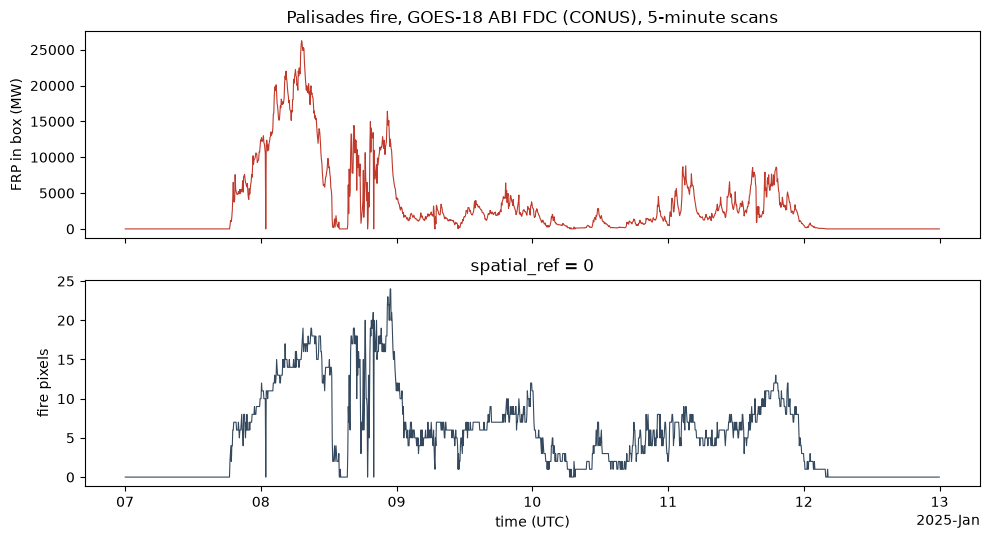

In [7]:
fig, (ax1, ax2) = plt.subplots(2, 1, figsize=(10, 5.5), sharex=True)
frp.plot(ax=ax1, lw=0.8, color="#c0392b")
ax1.set_ylabel("FRP in box (MW)")
ax1.set_xlabel("")
ax1.set_title("Palisades fire, GOES-18 ABI FDC (CONUS), 5-minute scans")
pixels.plot(ax=ax2, lw=0.8, color="#34495e")
ax2.set_ylabel("fire pixels")
ax2.set_xlabel("time (UTC)")
fig.tight_layout()

## 4. Map one scan

One time step of the cube is one netCDF file. This cell reads the scan with the highest FRP in the box, clipped to `MAP_BOUNDS`, and draws its FRP on a basemap.

The map stays in the fixed-grid CRS. The basemap tiles are warped to that CRS, and the data is not resampled, so each square on the map is one ABI pixel as the satellite saw it. The AOI box is densified before it is projected, so its edges follow the true shape of the lon/lat box on the grid.

27 fire pixels in the map area at 2025-01-08T07:12Z


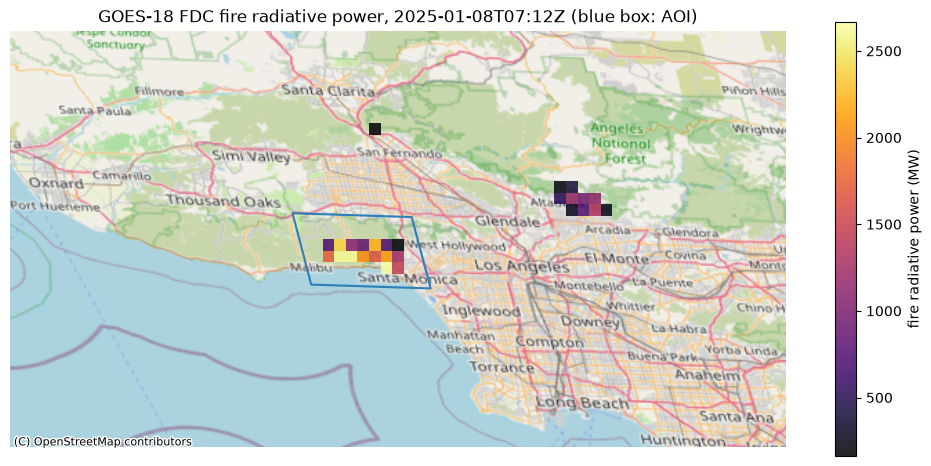

In [8]:
peak = frp.idxmax().values
scan = grid.sel(time=peak).rio.clip_box(*MAP_BOUNDS, crs="EPSG:4326")
scan_frp = scan.Power.where(scan.Power > 0).compute()
print(f"{int(scan_frp.notnull().sum())} fire pixels in the map area at {np.datetime_as_string(peak, unit='m')}Z")

fig, ax = plt.subplots(figsize=(10, 6.5))
scan_frp.plot.pcolormesh(
    ax=ax, cmap="inferno", alpha=0.85, cbar_kwargs={"label": "fire radiative power (MW)", "shrink": 0.7}
)
AOI.segmentize(0.005).to_crs(crs).boundary.plot(ax=ax, color="#2c7fb8", lw=1.5)
# The OpenStreetMap tile policy asks every client to identify itself. The
# servers block contextily's default User-Agent.
osm_headers = {"User-Agent": "goes-fdc-catalog notebook (https://github.com/mmidzik/goes-fdc-catalog)"}
cx.add_basemap(ax, crs=crs, source=cx.providers.OpenStreetMap.Mapnik, headers=osm_headers, zorder=0)
ax.set_aspect("equal")
ax.set_axis_off()
ax.set_title(f"GOES-18 FDC fire radiative power, {np.datetime_as_string(peak, unit='m')}Z (blue box: AOI)")
fig.tight_layout()

## 5. What the cube saved

Without the cube, the same answer starts with a list of every file in the window, then a download of each one. With the cube, the reader asks for the chunks that cover the box and nothing else.

In [9]:
ys = np.flatnonzero(grid.y.isin(fire.y).values)
xs = np.flatnonzero(grid.x.isin(fire.x).values)
cy, cx_ = ds.Power.encoding["chunks"][1:]
tiles = len(set(ys // cy)) * len(set(xs // cx_))
per_file = (ds.sizes["y"] // cy) * (ds.sizes["x"] // cx_)

print(f"netCDF files in the window:        {ds.sizes['time']:,}")
print(f"chunks per variable per file:      {per_file}")
print(f"chunks the box needs per variable: {tiles}")
print(f"chunk requests for Power and Mask: {2 * tiles * ds.sizes['time']:,}")

netCDF files in the window:        1,728
chunks per variable per file:      60
chunks the box needs per variable: 1
chunk requests for Power and Mask: 3,456


## What the catalog could not say

- **The virtual chunk container.** The reader needs NOAA's `https` prefix authorized before any read. The catalog has no field for it.
- **The store is a directory.** The `icechunk` asset is a repository, not one object, so it has no single `file:checksum` or `file:size`.
- **One grid per cube.** A virtual cube inherits the grid of its files. GOES-18 moved from -89.5 to -137.0 degrees in 2022, so its early files cannot join this cube. The catalog has no way to say which era a cube covers or to link the cube for another era.

These notes go to [portolan-spec#132](https://github.com/portolan-sdi/portolan-spec/issues/132).